In [14]:
import qiskit as q
import QiskitUtils as qkt
from qiskit import QuantumCircuit
from qiskit import QuantumRegister
from qiskit import ClassicalRegister
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [28]:
n = 5
q = 2
image_size = 2**n
max_intensity = 2**q
image = Image.open('input/image.jpeg')
image = image.resize((image_size,image_size),Image.NEAREST)
image = image.convert('L')

pixels = list(image.getdata())
image_q = [(pixels[i] >> (8 - q)) for i in range(len(pixels))]

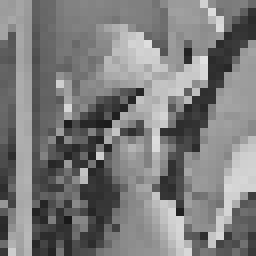

In [29]:
image.resize((256,256),Image.NEAREST)

In [30]:
def to_binary(num,total_bits):
    r = bin(num)[2:]
    r = '0'*(total_bits-len(r)) + r
    return r

In [31]:
def print_image(image):
    img_matrix = np.array(image).reshape((image_size, image_size))
    
    plt.imshow(img_matrix, cmap='gray', vmin=0, vmax=max_intensity - 1)
    plt.axis('off')
    plt.show()

In [32]:
def counts_to_pil(counts, n, q=0, has_I1=False, min_count=1,black_edges=True):
    size = 2 ** n
    skip = q if has_I1 else 0
    pix = [255 if black_edges else 0] * (size * size)
    edge = 0 if black_edges else 255

    for bits, c in counts.items():
        bits = bits.replace(' ', '')
        if c < min_count or bits[0] != '1':
            continue
        y = int(bits[1 + skip: 1 + skip + n], 2)
        x = int(bits[1 + skip + n: 1 + skip + 2 * n], 2)
        pix[y * size + x] = edge

    img = Image.new('L', (size, size))
    img.putdata(pix)
    return img


In [33]:
def get_Increment_gate(n_bits):
    Increment = QuantumCircuit(n_bits)
    for i in reversed(range(n_bits)):
        Increment.mcx(list(range(i)),i)
    Increment_gate = Increment.to_gate(label='Increment')
    return Increment_gate

def get_S2C_gate(n_bits):
    b = QuantumRegister(n_bits,'b')
    
    Increment_gate = get_Increment_gate(n_bits)
    
    S2C = QuantumCircuit(b)
    S2C.x(b)
    S2C.append(Increment_gate,S2C.qubits)
    S2C_gate = S2C.to_gate(label='S2C')
    return S2C_gate

def get_Add_gate(n_bits):
    c1 = QuantumRegister(1, 'c')
    b1 = QuantumRegister(1, 'b')
    a1 = QuantumRegister(1, 'a')

    MAJ = QuantumCircuit(c1, b1, a1)
    MAJ.cx(a1, b1)
    MAJ.cx(a1, c1)
    MAJ.ccx(b1, c1, a1)
    MAJ_gate = MAJ.to_gate(label='MAJ')

    UMA = QuantumCircuit(c1, b1, a1)
    UMA.ccx(b1, c1, a1)
    UMA.cx(a1, c1)
    UMA.cx(c1, b1)
    UMA_gate = UMA.to_gate(label='UMA')

    c0 = QuantumRegister(1, 'c0')
    a  = QuantumRegister(n_bits, 'a')
    b  = QuantumRegister(n_bits, 'b')
    z  = QuantumRegister(1, 'z')
    Add = QuantumCircuit(c0, a, b, z)
    
    Add.append(MAJ_gate, [c0[0], b[0], a[0]])
    for i in range(1, n_bits):
        Add.append(MAJ_gate, [a[i - 1], b[i], a[i]])

    Add.cx(a[n_bits - 1], z[0])

    for i in reversed(range(1, n_bits)):
        Add.append(UMA_gate, [a[i - 1], b[i], a[i]])
    Add.append(UMA_gate, [c0[0], b[0], a[0]])

    return Add.to_gate(label='Add')

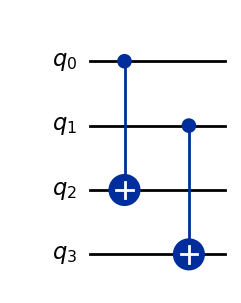

In [34]:
def get_Copy_gate(q_bits):
    src = QuantumRegister(q_bits, 'src')
    dst = QuantumRegister(q_bits, 'dst')
    copy_qc = QuantumCircuit(src, dst)
    for i in range(q_bits):
        copy_qc.cx(src[i], dst[i])
    return copy_qc.to_gate(label='Copy')

get_Copy_gate(q).definition.draw('mpl')

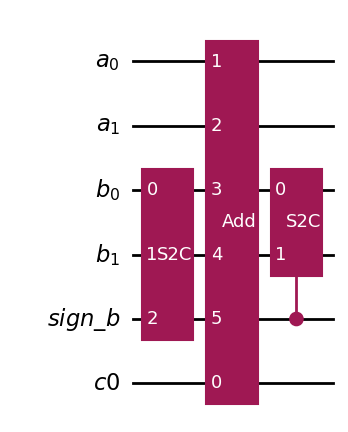

In [35]:
a = QuantumRegister(q, 'a')
b = QuantumRegister(q, 'b')
sign_b = QuantumRegister(1, 'sign_b')
c0 = QuantumRegister(1, 'c0')

Sub = QuantumCircuit(a, b, sign_b, c0)

S2C_n1 = get_S2C_gate(q + 1)
Add_gate = get_Add_gate(q)
S2C_n_ctrl = get_S2C_gate(q).control(1)

Sub.append(S2C_n1, list(b) + list(sign_b))
Sub.append(Add_gate, list(c0) + list(a) + list(b) + list(sign_b))
Sub.append(S2C_n_ctrl, list(sign_b) + list(b))
Sub_gate = Sub.to_gate(label='Sub')
Sub.draw('mpl')

In [36]:
x_r = QuantumRegister(n,'x')
y_r = QuantumRegister(n,'y')
I_r = QuantumRegister(q,'I')
c_r = ClassicalRegister(2*n+q+1,'c')
qc = QuantumCircuit(x_r,y_r,I_r)
oracle = QuantumCircuit(x_r,y_r,I_r)
pos_qubits = list(x_r)[::-1] + list(y_r)[::-1]

for pos,pixel in enumerate(image_q):
    x = pos % image_size
    y = pos // image_size
    pos_bin = to_binary(x, n) + to_binary(y, n)
    value_bin = to_binary(pixel,q)[::-1]

    zeros = [pos_qubits[k] for k in range(2*n) if pos_bin[k] == '0']
    for b in zeros:
        oracle.x(b)

    for b in range(q):
        if value_bin[b] == '1':
            oracle.mcx(pos_qubits, I_r[b])

    for b in zeros:
        oracle.x(b)

    #oracle.barrier()
    
oracle_gate = oracle.to_gate(label="NEQR")
#oracle.draw('mpl')

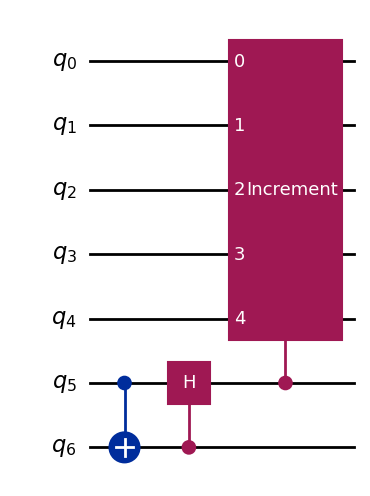

In [37]:
def get_Shift_gate(n_bits):
    x = QuantumRegister(n_bits, 'x')
    sign = QuantumRegister(1, 'sign')
    a = QuantumRegister(1, 'a')
    qc = QuantumCircuit(x, sign, a)

    qc.cx(sign[0], a[0])
    qc.ch(a[0], sign[0])

    inc = get_Increment_gate(n_bits)
    qc.append(inc.control(1), [sign[0]] + list(x))

    return qc.to_gate(label='Shift')

get_Shift_gate(n).definition.draw('mpl')

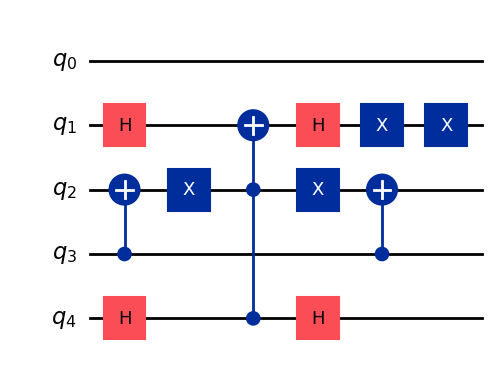

In [38]:
def get_Threshold_gate(q_bits, T):
    grad = QuantumRegister(q_bits, 'grad')
    sign = QuantumRegister(1, 'sign')
    a = QuantumRegister(1, 'a')
    out = QuantumRegister(1, 'out')
    qc = QuantumCircuit(grad, sign, a, out)

    t_bits = [(T >> i) & 1 for i in range(q_bits)]

    qc.cx(a[0], sign[0])
    qc.x(sign[0])
    flag = sign[0]

    qc.h(out[0])

    flipped = []
    for i in reversed(range(q_bits)):
        if t_bits[i] == 0:
            controls = [out[0], flag] + [grad[j] for j in range(i + 1, q_bits)]
            target = grad[i]
            qc.h(target)
            qc.mcx(controls, target)
            qc.h(target)
            qc.x(grad[i])
            flipped.append(i)
    for i in flipped:
        qc.x(grad[i])

    qc.h(out[0])

    qc.x(sign[0])
    qc.cx(a[0], sign[0])

    return qc.to_gate(label='Threshold')

get_Threshold_gate(q,5).definition.draw('mpl')

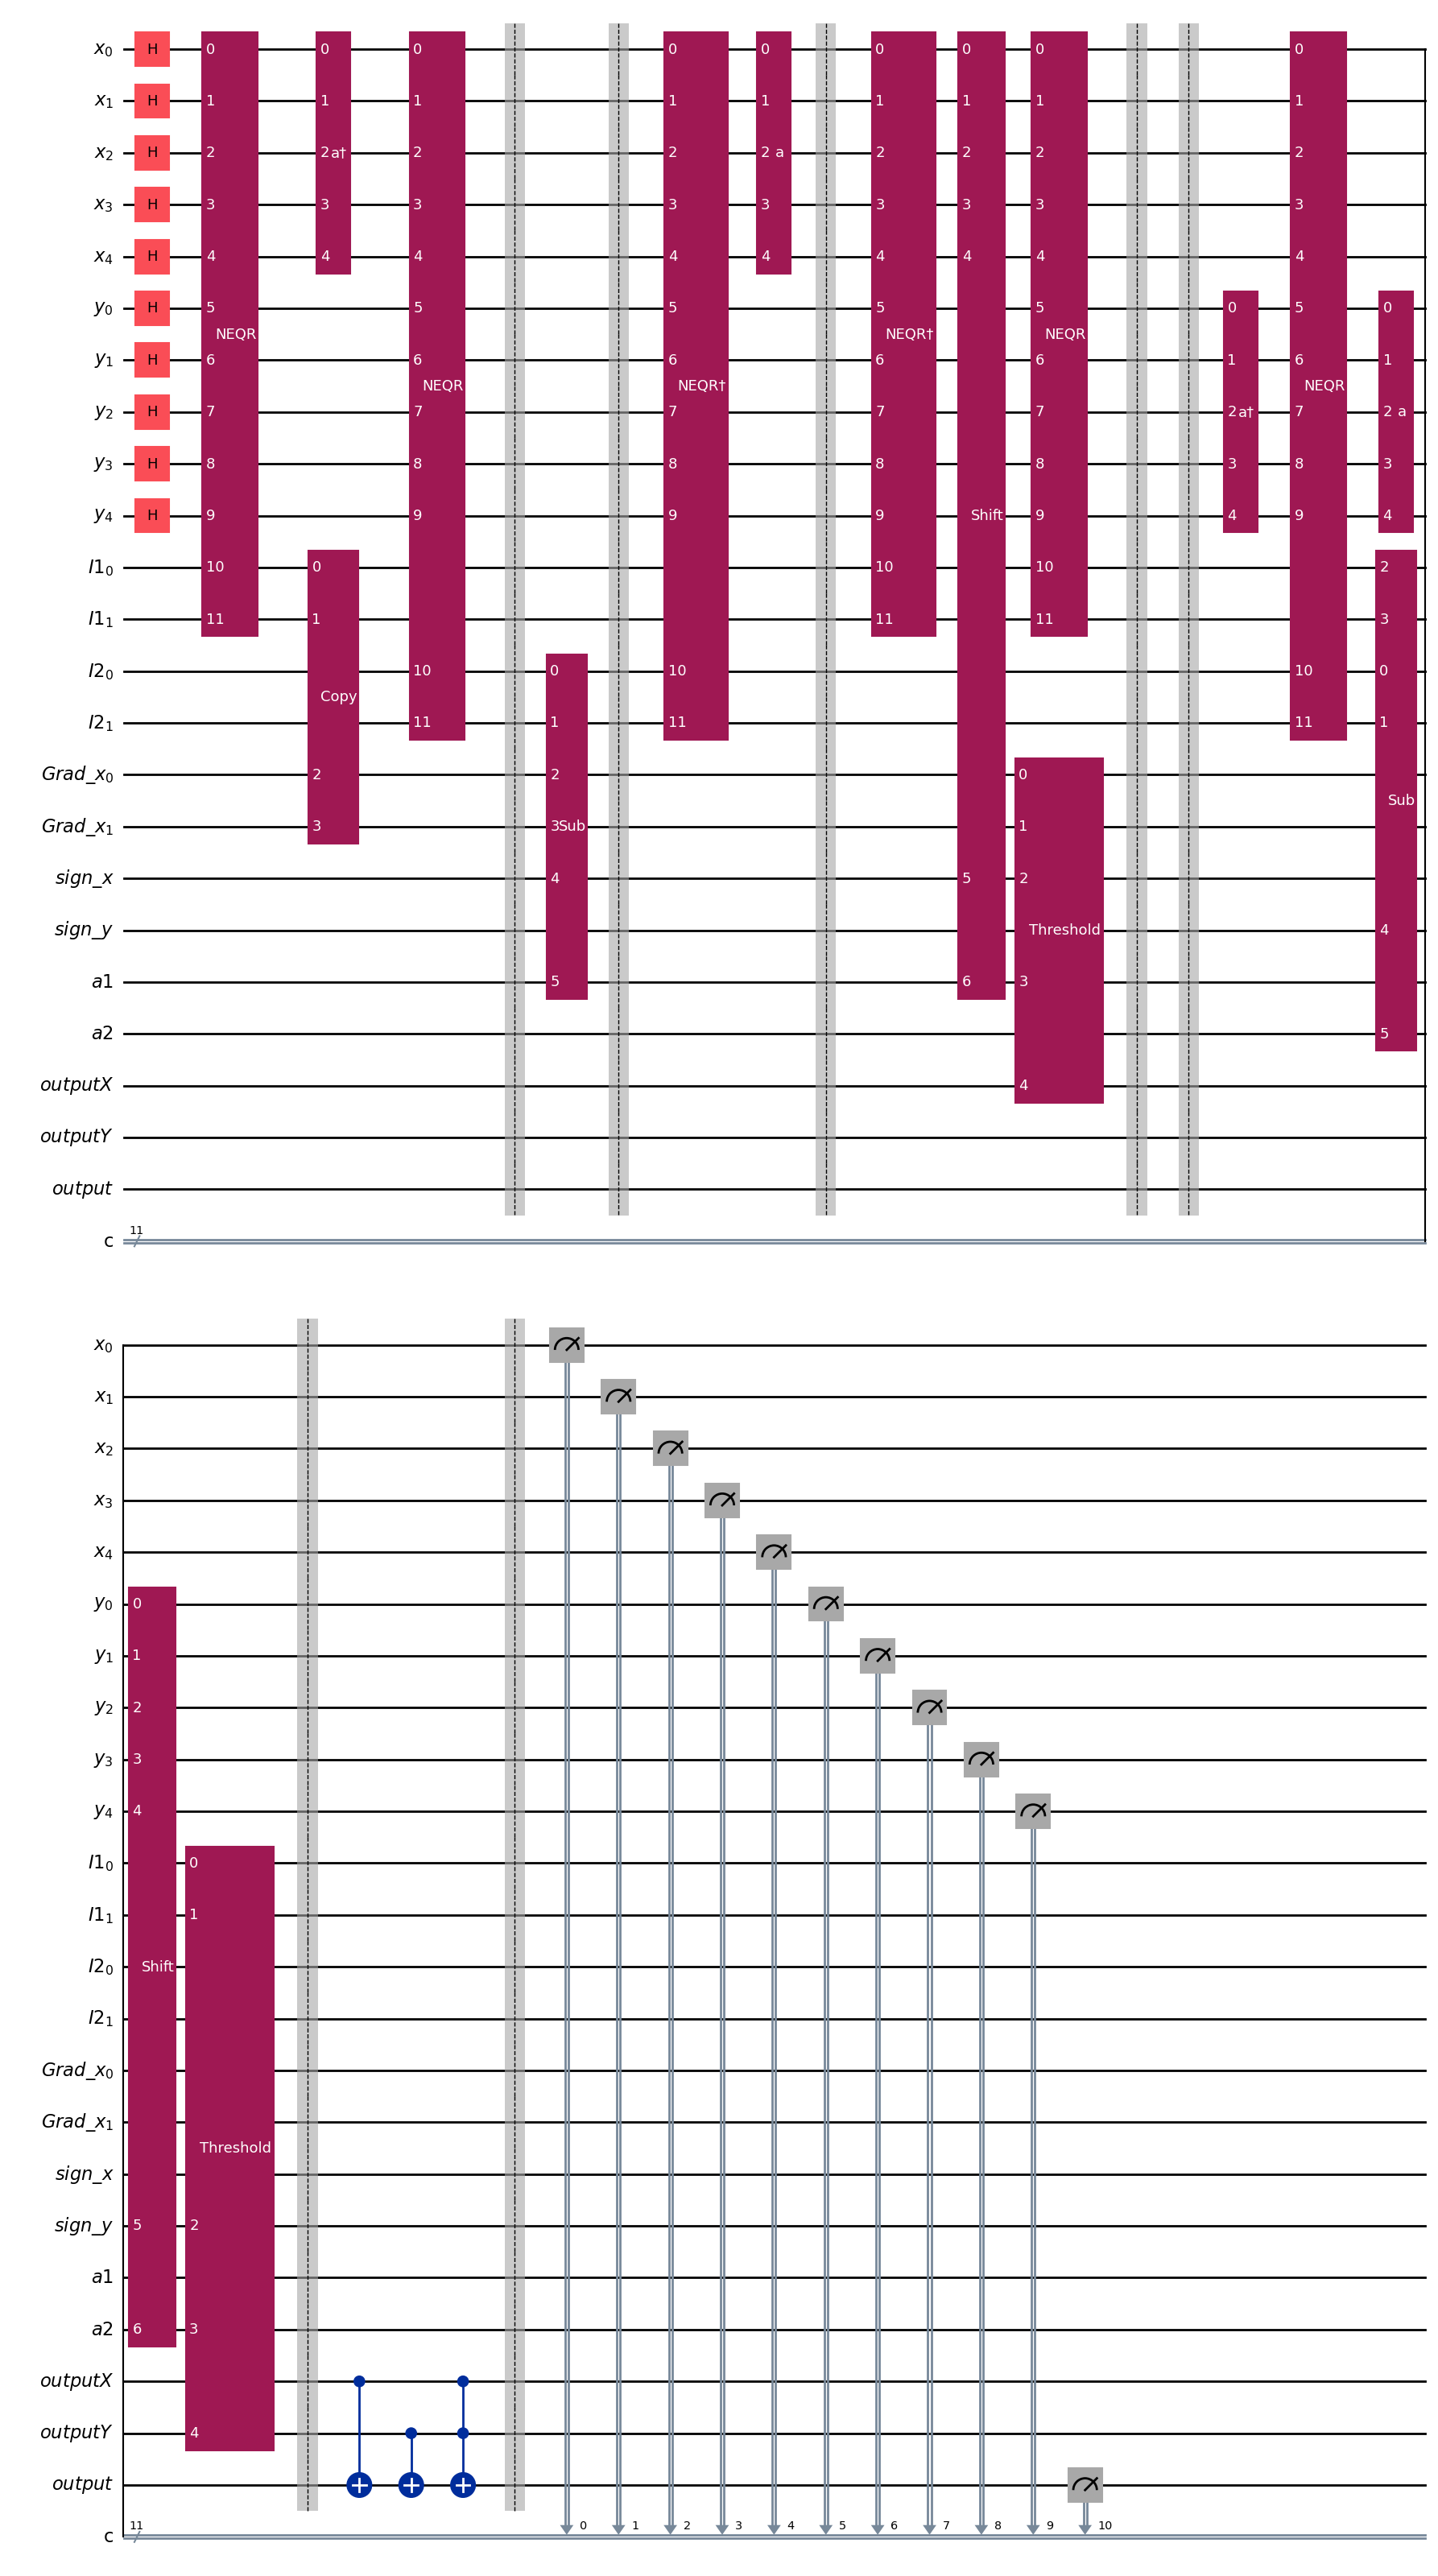

In [39]:
c_r = ClassicalRegister(2*n + 1,'c')

x_r = QuantumRegister(n,'x')
y_r = QuantumRegister(n,'y')
I1_r = QuantumRegister(q,'I1')
I2_r = QuantumRegister(q,'I2')
Grad_x = QuantumRegister(q,'Grad_x')
sign_x = QuantumRegister(1,'sign_x')
sign_y = QuantumRegister(1,'sign_y')
a1 = QuantumRegister(1,'a1')
a2 = QuantumRegister(1,'a2')
outputX = QuantumRegister(1,'outputX')
outputY = QuantumRegister(1,'outputY')
output = QuantumRegister(1,'output')

T = 2
a_gate = get_Increment_gate(n)
a_inv = a_gate.inverse()

a_gate.label = 'a†'
a_inv.label = 'a'

neqr_inv = oracle_gate.inverse()
neqr_inv.label = 'NEQR†'

qc = QuantumCircuit(x_r,y_r,I1_r,I2_r,Grad_x,sign_x,sign_y,a1,a2,outputX,outputY,output,c_r)
qc.h(x_r)
qc.h(y_r)
qc.append(oracle_gate,list(x_r)+list(y_r)+list(I1_r))
qc.append(a_gate,list(x_r))
qc.append(oracle_gate,list(x_r)+list(y_r)+list(I2_r))
qc.append(get_Copy_gate(q),list(I1_r)+list(Grad_x))

qc.barrier()
qc.append(Sub_gate,list(I2_r)+list(Grad_x)+list(sign_x)+list(a1))
qc.barrier()

qc.append(neqr_inv,list(x_r)+list(y_r)+list(I2_r))
qc.append(a_inv,list(x_r))
qc.barrier()

qc.append(neqr_inv,list(x_r)+list(y_r)+list(I1_r))
qc.append(get_Shift_gate(n),list(x_r)+list(sign_x)+list(a1))
qc.append(oracle_gate,list(x_r)+list(y_r)+list(I1_r))   
qc.append(get_Threshold_gate(q, T),list(Grad_x) + list(sign_x) + list(a1) + list(outputX))
qc.barrier()

qc.barrier()
qc.append(a_gate,list(y_r))
qc.append(oracle_gate,list(x_r)+list(y_r)+list(I2_r))
qc.append(a_inv,list(y_r))
qc.append(Sub_gate,list(I2_r)+list(I1_r)+list(sign_y)+list(a2)) 
qc.append(get_Shift_gate(n),list(y_r)+list(sign_y)+list(a2))
qc.append(get_Threshold_gate(q, T),list(I1_r) + list(sign_y) + list(a2) + list(outputY))
qc.barrier()

qc.cx(outputX,output)
qc.cx(outputY,output)
qc.ccx(outputX,outputY,output)

qc.barrier()
qc.measure(list(x_r)+list(y_r)+list(output),list(c_r))

qc.draw('mpl')

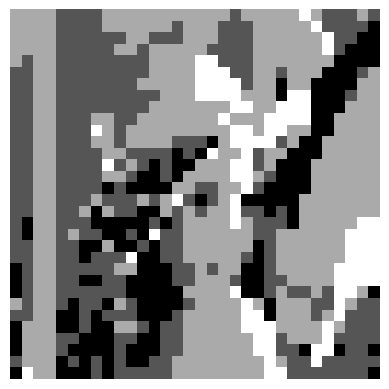

In [40]:
print_image(image_q)

In [41]:
from qiskit_aer import AerSimulator
from qiskit import transpile
simulator = AerSimulator(
    method="statevector",
    max_parallel_threads=8,
    statevector_parallel_threshold=14
)
compiled_circuit = transpile(qc, simulator)
job = simulator.run(compiled_circuit, shots=10000)
result = job.result()  
counts = result.get_counts(compiled_circuit)



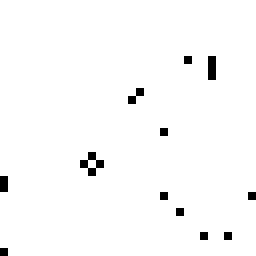

In [42]:
counts_to_pil(counts,n,q).resize((256,256),Image.NEAREST)

In [173]:
"""
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="0JKh_4PkGDXojZPRqueiWMo-09YonruRwdWXC9H1XzWF",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/9490fcb2791045a4bd51fcadf85a41ae:a169fd0d-e33d-40b9-bbdc-05a55969d6f3::",
    overwrite=True,
    set_as_default=True
)

service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False, min_num_qubits=qc.num_qubits)

isa = generate_preset_pass_manager(backend=backend, optimization_level=3).run(qc)
result = Sampler(mode=backend).run([isa], shots=10000).result()
counts = result[0].data.c.get_counts()

counts_to_pil(counts, n, q, min_count=10).resize((256,256), Image.NEAREST).save("pk1_edges.png")
"""

/var/folders/_9/z9jz74hs6yz5qsjxdzrfw3d40000gn/T/ipykernel_7335/3312638014.py:16: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  result = Sampler(mode=backend).run([isa], shots=10000).result()


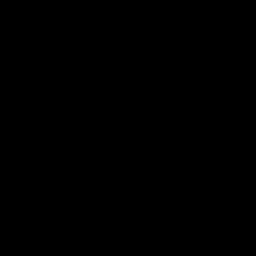

In [208]:
output_image = counts_to_pil(counts, n, q, min_count=10).resize((256,256), Image.NEAREST)
output_image.save()

In [207]:
counts

{'1000001': 151,
 '0001101': 104,
 '0001001': 130,
 '1101100': 52,
 '0110000': 98,
 '0001011': 75,
 '0100000': 100,
 '0010001': 104,
 '1111001': 66,
 '0000000': 229,
 '0101001': 83,
 '1111100': 81,
 '0010000': 134,
 '1000101': 95,
 '1011100': 73,
 '1110100': 84,
 '0000111': 64,
 '0001010': 126,
 '0010110': 70,
 '0000011': 82,
 '0000001': 160,
 '0010100': 115,
 '0000100': 170,
 '0000010': 145,
 '1000000': 207,
 '0110001': 74,
 '1111010': 72,
 '1010011': 51,
 '0010101': 72,
 '1011110': 50,
 '0111000': 113,
 '0001000': 172,
 '1010001': 86,
 '1010100': 92,
 '0010111': 39,
 '1001110': 100,
 '0100111': 27,
 '0011000': 125,
 '0101010': 65,
 '0101111': 36,
 '0011001': 101,
 '0111011': 50,
 '1110111': 41,
 '0110100': 81,
 '0111100': 87,
 '0011011': 65,
 '0100100': 81,
 '0011100': 96,
 '0101101': 49,
 '1101011': 38,
 '1001100': 127,
 '1000100': 144,
 '1010000': 144,
 '0111110': 59,
 '1001000': 157,
 '1110110': 45,
 '0101100': 77,
 '0110111': 37,
 '1001011': 69,
 '1111000': 97,
 '1000111': 57,
 '